# Figure 2 — potential temperature and salinity, BGOSE6 shelves on vs shelves off

Reproduces `Fig2_TS.png` of the manuscript: the **difference** in potential temperature θ and
salinity *S* between two BGOSE6 runs that are identical except that one resolves ice-shelf cavity
thermodynamics (*shelves on*) and the other does not (*shelves off*).

| panel | content |
|---|---|
| **a, b** | ΔS, Δθ averaged **above** the γⁿ = 27.95 surface |
| **c, d** | ΔS, Δθ averaged **below** it, down to 1000 m |
| **e, f** | ΔS, Δθ on a 120°W section, 75°S–72°S, 0–1000 m |



### Starting point

This notebook begins from **post-processed products**, not raw model output. Turning ~40 TB of
BGOSE6 5-day and monthly files into annual means is a separate, slow step; the scripts that do it
are named in §2 so the chain is auditable, but none of them run here.



## 1. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')

import numpy as np
import xarray as xr
import netCDF4 as nc
from scipy import stats

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.collections import QuadMesh
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

%matplotlib inline

D    = '/data/globus/zkaufman/'                              # post-processed products
REPO = '/home/zkaufman/Notebooks/ASC_analysis_SoHi/'         # figure output
RUNS = ['shelveson', 'shelvesoff']

### Domain

Longitude bounds come from the adopted Amundsen–Bellingshausen sector (`scripts/warm_shelf/`);
the latitude range is a plotting window, not part of the definition. The map is drawn **wider**
than the domain so the Antarctic Peninsula is in frame for orientation — colour stops at `LO1`,
which is marked with a dashed meridian.

In [2]:
LO0, LO1 = 212.17, 283.67     # 147.83°W → 76.33°W: THE DOMAIN
MAP_LO1  = 295.0              # 65°W: map frame only, so the Peninsula is visible
LA0, LA1 = -78.0, -68.0       # plotting window

XSEC      = 239.91778564453125   # the 120°W section's actual tracer-grid column
PLOT_LAT0 = -75.0                # section latitude range
SEC_LAT1  = -72.0
ZBOT      = 1000.0               # base of the lower band and of the section
ZMIN      = -1000.0

### House style

AGU/GRL two-column figures are 105–170 mm wide at 300–600 ppi, with figure text at **6 pt**
(smaller than the 8 pt other AGU journals use). The figure is built at exactly 170 mm so that
matplotlib points *are* printed points — no rescaling at submission.

In [3]:
FIG_W_MM, FIG_H_MM = 170.0, 152.0
MM, DPI = 1 / 25.4, 400
FS_TICK, FS_TITLE, FS_PANEL = 6, 7, 8      # 6 pt is the GRL minimum
LW = 0.55                                   # contour weight at this size

INK, INK2, GRID = '#0b0b0b', '#52514e', '#d8d7d2'
PINK            = '#ff2e93'                 # the section's location line on panel a
ICE_EDGE, LW_ICE = '#5c5c5c', 1.4           # ice-shelf outline
C_ROCK, C_ICE    = '#b3a161', '#c8dcf0'     # section bed and ice shelf
HATCH, HATCH_COLOR = '//////', '#4a4a4a'    # "not significant"
DASH  = (0, (3.0, 1.6))                     # shelves-off γⁿ contours
DENSE = [27.8, 27.9, 28.0]                  # the three γⁿ surfaces drawn on e–f
ALPHA = 0.05
PANEL = 'abcdef'

matplotlib.rcParams['hatch.linewidth'] = 0.3
matplotlib.rcParams['hatch.color'] = '#9a968e'

# Salinity LEFT, temperature RIGHT. Each entry: (variable, panel title, colormap, colourbar label).
VARS = [('salt',  'ΔS, shelves on − shelves off',  'BrBG_r', 'ΔS'),
        ('theta', 'Δθ, shelves on − shelves off',  'RdBu_r', 'Δθ  (°C)')]

## 2. Input data

Three post-processed products, all already reduced to annual means on the sector subgrid.

| file | made by | what it holds |
|---|---|---|
| `TSannual_BGOSE6_{run}_148Wto76W_78Sto68S_2013to2025.nc` | `ts_annual_prep.py` | 3-D annual means `θ_3d`, `salt_3d` (year, depth, lat, lon); the 120°W section `*_sec`; `hFacC` |
| `TSgammaSplit_BGOSE6_{run}_148Wto76W_shelf_2013to2025.nc` | `ts_gamma_split_prep.py` | band means above/below each record's **own** γⁿ = 27.95 surface, **shelf only** |
| `Transect120W_BGOSE6_{run}_20130101to20251231.nc` | `transect_120W_shelveson_vs_off.py` | the section's time-mean θ, S, σ₀ and the geometry (`rLowC`, `rSurfC`, `drF`) needed to draw bed and ice |

`*_recmean` variables are the plain 2013–2025 record mean of each run (monthly records for
shelves-on, 5-day for shelves-off). The displayed difference is `recmean_on − recmean_off`.

In [4]:
SPAN = '20130101to20251231'

TS  = {r: xr.open_dataset(D + f'TSannual_BGOSE6_{r}_148Wto76W_78Sto68S_2013to2025.nc') for r in RUNS}
GS  = {r: xr.open_dataset(D + f'TSgammaSplit_BGOSE6_{r}_148Wto76W_shelf_2013to2025.nc') for r in RUNS}
SEC = {r: xr.open_dataset(D + f'Transect120W_BGOSE6_{r}_{SPAN}.nc') for r in RUNS}

on, off = TS['shelveson'], TS['shelvesoff']
print(f'TS annual   : {dict(on.sizes)}')
print(f'gamma split : {dict(GS["shelveson"].sizes)}')
print(f'section     : {dict(SEC["shelveson"].sizes)}')
print(f'years       : {on.year.values[0]}–{on.year.values[-1]}  ({on.sizes["year"]})')
print(f'records/run : on {int(on.n_records.sum())} monthly, off {int(off.n_records.sum())} 5-day')

TS annual   : {'year': 13, 'band': 2, 'lat': 160, 'lon': 429, 'depth': 37}
gamma split : {'year': 13, 'lat': 160, 'lon': 429}
section     : {'depth': 37, 'lat': 80}
years       : 2013–2025  (13)
records/run : on 156 monthly, off 949 5-day


### Coordinate guard

Float32 coordinates written by different parts of the model chain have silently mis-aligned
before: xarray's default `arithmetic_join="inner"` then drops the non-matching cells **partially
and without warning**, so a difference map can lose half its grid and still look plausible. Every
cross-file operation below is on raw `.values` with shapes asserted first.

In [5]:
assert np.array_equal(on.lat.values, off.lat.values), 'TS latitudes differ between runs'
assert np.array_equal(on.year.values, off.year.values) and on.sizes['year'] == 13
for r in RUNS:
    assert np.allclose(GS[r].lat.values, on.lat.values), f'{r}: gamma-split latitudes'
    assert np.allclose(GS[r].lon.values, on.lon.values), f'{r}: gamma-split longitudes'
assert abs(on.attrs['section_lon'] - XSEC) < 1e-4, 'section longitude'
print('coordinates aligned across all six input files')

coordinates aligned across all six input files


## 3. Grid geometry

Land, ice-shelf cavities and bathymetry over the **map** frame, which is wider than the data
domain.

Two traps are worth stating because both have caused real errors here:

- **`Depth` in these files is water-column *thickness*, not bathymetry.** Land is `Depth <= 0`;
  the sea floor on a section comes from `rLowC`, never from `Depth`.
- **Geometry is read from a model output file, not from `grid.nc`.** `grid.nc` stores `XC`/`YC`
  in float64 that differ from the output files' float32 by up to 0.004°, and it carries no
  `rSurfC`, so cavities cannot be identified from it at all. Reading geometry from an output file
  guarantees the masks sit on exactly the grid the data sit on.

In [6]:
# Any BGOSE6 output file serves — these are static 2-D fields, not a time series.
GEOM  = '/data/globus/BGOSE/RUN6/ITER042_ShelvesOff/OUTPUT/5DAY/2013/Theta_bgoseI042_2013_5day.nc'
BATHY = D + 'bathym_BGOSE6_I042.nc'

def geometry(lo0, lo1, la0, la1):
    """Latitudes, longitudes, land mask and cavity mask over the map frame."""
    d = nc.Dataset(GEOM); d.set_auto_mask(False)
    YC, XC = np.asarray(d['YC'][:]), np.asarray(d['XC'][:])
    jy = np.where((YC >= la0) & (YC <= la1))[0]
    ix = np.where((XC >= lo0) & (XC <= lo1))[0]
    y0, y1, x0, x1 = jy.min(), jy.max() + 1, ix.min(), ix.max() + 1
    thick  = np.asarray(d['Depth'][y0:y1, x0:x1])      # column THICKNESS, not bathymetry
    rSurfC = np.asarray(d['rSurfC'][y0:y1, x0:x1])     # ice draft; < 0 inside a cavity
    land = thick <= 0
    return YC[y0:y1], XC[x0:x1], land, (rSurfC < 0) & ~land

ba, bl, land, cav = geometry(LO0, MAP_LO1, LA0, LA1)

# The data subgrid must be an exact leading slice of the wider map grid.
nlon = on.sizes['lon']
assert np.allclose(ba, on.lat.values) and np.allclose(bl[:nlon], on.lon.values), \
       'geometry coords do not match the TS subgrid'

H = (xr.open_dataset(BATHY).bathymetry
       .sel(lon=slice(LO0, MAP_LO1), lat=slice(LA0, LA1)).values.astype(float))
print(f'map frame {land.shape} | {land.sum()} land cells, {cav.sum()} cavity cells')

map frame (160, 497) | 27464 land cells, 12237 cavity cells


### Ice-shelf labels

Cavity centres are loaded from a cache. Deriving them is a side quest — BGOSE6's cavities form one
connected component along this coast, so separating them needs a labelled ID field remapped from
the 1/24° SOhi grid by nearest neighbour. That is documented in
`scripts/along_slope_velocity/map_ualong_cdwsplit_newdomain.py::ice_shelf_centres`; here only the
result matters.

In [7]:
_z = np.load(D + 'IceShelfCentres_BGOSE6_ABsector.npz')
CENTRES = {str(n): (float(x), float(y)) for n, x, y in zip(_z['names'], _z['lon'], _z['lat'])}
LAB_W, LAB_E = 217.0, 279.7   # the label row spans Getz → Stange, evenly
LABEL_ROW_DY = 0.55           # row height above the panel's south edge
print(', '.join(sorted(CENTRES, key=lambda k: CENTRES[k][0])))

Getz, Dotson, Crosson, Thwaites, Pine Island, Cosgrove, Abbot, Venable, Stange


## 4. The two vertical bands

### 4a. The published split: γⁿ = 27.95 (used for panels a–d)

Each record is split at **its own** γⁿ = 27.95 depth, so the averaging depth differs between runs
and through time. That is the point: 27.95 is the threshold separating Circumpolar Deep Water from
the lighter shelf water above it, and comparing a fixed depth across two runs whose density
structure differs would confound a layer shift with a property change.

Rules baked into `ts_gamma_split_prep.py`:

- Upper = above the surface; lower = below it, **capped at 1000 m**.
- A column with no 27.95 water in a given record is **all upper** for that record.
- Means and the *t*-test use only the records in which the band exists (NaN-omitting).
- **Shelf only.** This product is masked to the continental shelf.

In [8]:
def gamma_bands(run, var):
    """(annual (year, 2, lat, lon), record-mean (2, lat, lon)) for the gamma^n = 27.95 split."""
    g = GS[run]
    ann = np.stack([g[f'{var}_upper'].values, g[f'{var}_lower'].values], axis=1)
    rec = np.stack([g[f'{var}_upper_recmean'].values, g[f'{var}_lower_recmean'].values])
    return ann, rec

BANDS = ['above γ$^n$ = 27.95', 'below γ$^n$ = 27.95']
_a, _r = gamma_bands('shelveson', 'theta')
print(f'annual {_a.shape} (year, band, lat, lon) | record mean {_r.shape}')
print(f'cells with a lower band: {np.isfinite(_r[1]).sum()} of {_r[1].size}')

annual (13, 2, 160, 429) (year, band, lat, lon) | record mean (2, 160, 429)
cells with a lower band: 15632 of 68640


### 4b. Alternative: a fixed-depth split

The earlier version of the figure split at a fixed **450 m**, which is the zero crossing of the
shelf-area-mean on − off θ profile over the open Amundsen shelf: meltwater-plume **cooling** above
(peaking at −1.1 °C near 150 m), CDW **warming** below (+0.18 °C near 600 m, ending ~950 m — hence
the 1000 m base).

That crossing is strongly regional — ~615 m in Amundsen cavities, ~310 m in Bellingshausen
cavities, ~115 m on the open Bellingshausen shelf — so no single depth tracks both sectors. 450 m
follows the Amundsen, where the plume signal dominates. The γⁿ split in §4a was adopted precisely
to avoid having to make that choice.

Shown because it is the natural starting point if your own comparison has no density product,
and because it works off `*_3d` directly, so **any** split depth is a re-slice rather than a re-read.

In [9]:
def depth_weights(drF, zmax):
    """Thickness per level clipped to the top `zmax` m, so a straddling cell is split, not dropped."""
    drF = np.abs(np.asarray(drF, dtype='f8'))
    bot = np.cumsum(drF)
    return np.clip(np.minimum(bot, zmax) - (bot - drF), 0.0, None)

def depth_bands(run, var, zsplit=450.0):
    """Thickness-weighted band means over [0, zsplit] and [zsplit, ZBOT] from the 3-D annual means."""
    ds  = TS[run]
    drF = np.abs(ds.drF.values.astype('f8')) if 'drF' in ds else None
    wet = ds.hFacC.values > 0
    ann, rec = [], []
    for zlo, zhi in ((0.0, zsplit), (zsplit, ZBOT)):
        w  = np.clip(depth_weights(drF, zhi) - depth_weights(drF, zlo), 0.0, None)
        w3 = w[:, None, None] * wet                  # zero weight on dry cells
        den = np.where(w3.sum(0) > 0, w3.sum(0), np.nan)
        ann.append(np.nansum(ds[f'{var}_3d'].values * w3[None], axis=1) / den[None])
        rec.append(np.nansum(ds[f'{var}_3d_recmean'].values * w3, axis=0) / den)
    return np.stack(ann, axis=1), np.stack(rec)

# Not used for the published figure — set SPLIT = 'depth' below to switch.
SPLIT = 'gamma'
bands_of = gamma_bands if SPLIT == 'gamma' else depth_bands
print(f'using the {SPLIT} split')

using the gamma split


## 5. *(Optional)* Computing neutral density γⁿ

**Skip this section if you are reusing the map format.** The result is cached and loaded in the
next cell; nothing below depends on running the computation.

γⁿ (Jackett & McDougall 1997) is needed twice: for the band boundaries in §4a, and for the three
contour surfaces drawn on panels e–f. Two practical notes for anyone reproducing it:

- **`pygamma_n` is conda-forge only and needs `libgfortran5 ≥ 14.3`.** Installing it into the
  analysis environment would upgrade the compiler runtime under the whole stack, so it lives in an
  isolated env (`envs/gamman`) and is called **out of process** via a `.npz` hand-off.
- **γⁿ wants practical salinity and *in-situ* temperature.** The model carries potential
  temperature, so the input must be round-tripped `SP, θ → SA → CT → t_insitu` with TEOS-10.
  Skipping that round-trip biases γⁿ by order 0.01 kg m⁻³.
- **σ₀ is not a usable substitute at this threshold.** Measured on this transect,
  γⁿ − σ₀ = +0.20 kg m⁻³, and σ₀ peaks at 27.82 in the domain — so a σ₀ = 27.95 surface does not
  exist anywhere and returns all-NaN.

In [10]:
# What was run, once, per run. Left unexecuted: it needs the isolated env and ~1 min per transect.
GAMMA_SRC = r"""
import gsw, numpy as np, subprocess

wet   = ds.hFacC.values > 0
theta = np.where(wet, ds.theta.values, np.nan)[None].astype('f8')   # (1, nz, nlat)
salt  = np.where(wet, ds.salt.values,  np.nan)[None].astype('f8')
lat   = np.broadcast_to(ds.lat.values[None, None, :], theta.shape).astype('f8')
Zg    = np.broadcast_to(ds.depth.values[None, :, None], theta.shape).astype('f8')
lon0  = ds.attrs['lon_XC']
lon   = np.full_like(lat, lon0 - 360.0 if lon0 > 180 else lon0)     # gamma_n wants -180..180

pr       = gsw.p_from_z(Zg, lat)                 # potential -> in-situ temperature
SA       = gsw.SA_from_SP(salt, pr, lon, lat)
CT       = gsw.CT_from_pt(SA, theta)
t_insitu = gsw.t_from_CT(SA, CT, pr)

np.savez('tgin.npz', SP=salt, t=t_insitu, p=pr, lon=lon, lat=lat)
subprocess.run(['/home/zkaufman/miniconda3/envs/gamman/bin/python',
                'undercurrent_melt_scripts/02_gamma_n_worker.py', 'tgin.npz', 'tgout.npz'],
               check=True)                        # worker calls pygamma_n.gamma_n(S, t, p, lon, lat)
gamma_n = np.where(wet, np.load('tgout.npz')['gamma'][0], np.nan)
"""
print(GAMMA_SRC)


import gsw, numpy as np, subprocess

wet   = ds.hFacC.values > 0
theta = np.where(wet, ds.theta.values, np.nan)[None].astype('f8')   # (1, nz, nlat)
salt  = np.where(wet, ds.salt.values,  np.nan)[None].astype('f8')
lat   = np.broadcast_to(ds.lat.values[None, None, :], theta.shape).astype('f8')
Zg    = np.broadcast_to(ds.depth.values[None, :, None], theta.shape).astype('f8')
lon0  = ds.attrs['lon_XC']
lon   = np.full_like(lat, lon0 - 360.0 if lon0 > 180 else lon0)     # gamma_n wants -180..180

pr       = gsw.p_from_z(Zg, lat)                 # potential -> in-situ temperature
SA       = gsw.SA_from_SP(salt, pr, lon, lat)
CT       = gsw.CT_from_pt(SA, theta)
t_insitu = gsw.t_from_CT(SA, CT, pr)

np.savez('tgin.npz', SP=salt, t=t_insitu, p=pr, lon=lon, lat=lat)
subprocess.run(['/home/zkaufman/miniconda3/envs/gamman/bin/python',
                'undercurrent_melt_scripts/02_gamma_n_worker.py', 'tgin.npz', 'tgout.npz'],
               check=True)                        # worker calls pyga

In [11]:
# The cached result — this is what the figure actually uses.
GAM = {r: xr.open_dataset(D + f'Transect120W_gamman_BGOSE6_{r}_{SPAN}.nc').gamma_n.values
       for r in RUNS}
for r in RUNS:
    g, s = GAM[r], SEC[r].sigma0.values
    print(f'{r:11s} gamma^n range {np.nanmin(g):.2f}–{np.nanmax(g):.2f} | '
          f'mean gamma^n − sigma_0 = {np.nanmean(g - s):+.3f} kg/m3')

shelveson   gamma^n range 25.71–28.31 | mean gamma^n − sigma_0 = +0.194 kg/m3
shelvesoff  gamma^n range 11.41–28.10 | mean gamma^n − sigma_0 = +0.067 kg/m3


## 6. Differences and significance

**The difference** is the plain 2013–2025 record mean of each run, differenced:
`recmean_on − recmean_off`.

**The test** is a two-sided **paired** *t*-test on the 13 **annual-mean** differences (12 dof).

- *Annual* because monthly and 5-day records are strongly autocorrelated — testing 156 monthly
  values would inflate the effective sample size several-fold and manufacture significance.
- *Paired* because both runs share the same atmospheric forcing year by year, so the common
  interannual signal cancels in the difference and the test sees only the cavity effect.

Hatching marks cells that are **not** significant (p ≥ 0.05). Cells where p is undefined — too few
records with a valid band — are treated as not significant, which is the conservative direction.



In [12]:
DIF, NS = {}, {}

for var, *_ in VARS:
    B = {r: bands_of(r, var) for r in RUNS}
    for kind in ('band', 'sec'):
        if kind == 'band':
            (ya, ra), (yb, rb) = B['shelveson'], B['shelvesoff']
        else:                                    # the 120W section, straight from TSannual
            ya, ra = on[f'{var}_sec'].values, on[f'{var}_sec_recmean'].values
            yb, rb = off[f'{var}_sec'].values, off[f'{var}_sec_recmean'].values

        d = ra - rb
        with np.errstate(invalid='ignore', divide='ignore'):
            if SPLIT == 'gamma' and kind == 'band':   # some years lack the band in a cell
                _, p = stats.ttest_rel(ya, yb, axis=0, nan_policy='omit')
                p = np.ma.filled(p, np.nan) if np.ma.isMaskedArray(p) else p
            else:
                _, p = stats.ttest_rel(ya, yb, axis=0)
        DIF[(var, kind)] = d
        NS[(var, kind)] = np.isfinite(d) & ~(p < ALPHA)     # NaN p -> not significant

## 7. Colour limits

**One limit per variable**, shared by that variable's two maps *and* its section, set to the 99th
percentile of |difference| over the **map** panels.

The section's salinity difference is far larger than that — meltwater enters the cavities only in
the shelves-on run — so panel e saturates **by design**, and the colour bars carry extend arrows to
say so. The alternative, a per-panel scale, would mean a colour had a different value in panel a
than in panel e, which is worse in a composite figure: a reader comparing a map with a section has
to be able to trust that the colours mean the same thing.

`TwoSlopeNorm` with `vcenter=0` pins white to zero, so the sign of a difference is never ambiguous.

In [13]:
LIM = {}
for var, *_ in VARS:
    m = DIF[(var, 'band')]
    LIM[var] = round(float(np.nanpercentile(np.abs(m), 99)), 2)
    s = DIF[(var, 'sec')]
    print(f'{var:6s} limit ±{LIM[var]:<5} | not significant: '
          f'upper {100 * NS[(var, "band")][0][np.isfinite(m[0])].mean():.0f}%, '
          f'lower {100 * NS[(var, "band")][1][np.isfinite(m[1])].mean():.0f}% '
          f'| section cells saturating: {100 * (np.abs(s[np.isfinite(s)]) > LIM[var]).mean():.1f}%')

salt   limit ±0.52  | not significant: upper 23%, lower 36% | section cells saturating: 5.4%
theta  limit ±1.41  | not significant: upper 22%, lower 53% | section cells saturating: 6.1%


## 8. The figure

### 8a. Two drawing helpers

`hatch` overlays the non-significant mask as hatching with no fill, so the value underneath stays
readable. `draw_masks` fills a section's rock and ice. Both need **cell edges**, not centres:
`shading='flat'` wants one more edge than cell in each direction, so depth edges come from the
cumulative `drF` and latitude edges from midpoints with the two ends extrapolated.

In [14]:
def hatch(ax, x, y, nonsig):
    """Hatch the not-significant region: grey hatch, no fill, no outline."""
    if not nonsig.any():
        return
    cs = ax.contourf(x, y, nonsig.astype(float), levels=[0.5, 1.5],
                     colors='none', hatches=[HATCH], zorder=3.5)
    cs.set_edgecolor(HATCH_COLOR)
    cs.set_linewidth(0.0)

def draw_masks(ax, lat, drF, rLowC, rSurfC):
    """Rock below rLowC, ice shelf above rSurfC. The sea floor is rLowC, NOT `Depth`."""
    z_edge = np.concatenate([[0.0], -np.cumsum(drF)])                 # (nz+1,)
    lat_e  = np.concatenate([[lat[0] - (lat[1] - lat[0]) / 2],
                             (lat[:-1] + lat[1:]) / 2,
                             [lat[-1] + (lat[-1] - lat[-2]) / 2]])    # (nlat+1,)
    z_top, z_bot = z_edge[:-1, None], z_edge[1:, None]
    rock = z_top < rLowC[None, :]
    ice  = (z_bot > rSurfC[None, :]) & (rSurfC[None, :] < 0)
    for mask, colour in ((rock, C_ROCK), (ice, '#c9c6bf')):
        ax.pcolormesh(lat_e, z_edge, np.where(mask, 1.0, np.nan),
                      cmap=ListedColormap([colour]), shading='flat', zorder=4)

### 8b. Maps (a–d)

Layer order matters and is set with explicit `zorder`: values (1) → hatching (3.5) → land and
cavities (4) → ice-shelf outline (4.2) → bathymetry contours (5) → domain edge (6) → section line
(8) → panel letter (10).

Two deliberate asymmetries:

- **Cavities are greyed out in the upper band only.** Above γⁿ = 27.95 the cavity values are a
  near-cancelling mix dominated by the plume and would hijack the colour scale; below it they are
  the signal, so c–d show them.
- **Aspect is locked to `1/cos(73°)`**, so the maps are true-scale at the centre of the domain
  rather than stretched to fill the axes.

maps a–d drawn


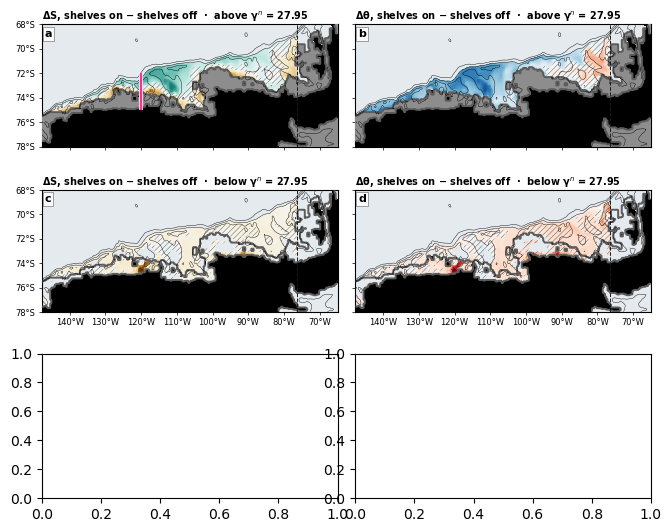

In [15]:
fig = plt.figure(figsize=(FIG_W_MM * MM, FIG_H_MM * MM))
gs  = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 1.15], hspace=0.30, wspace=0.06,
                       left=0.075, right=0.985, top=0.967, bottom=0.172)
axes = [[fig.add_subplot(gs[r, c]) for c in range(2)] for r in range(3)]
pcms, n = {}, 0

for r, blab in enumerate(BANDS):
    for c, (var, vname, cmap, _) in enumerate(VARS):
        ax = axes[r][c]
        ax.set_facecolor('#e4eaee')                       # open ocean beyond the data
        norm = TwoSlopeNorm(vmin=-LIM[var], vcenter=0.0, vmax=LIM[var])

        pcms[var] = ax.pcolormesh(on.lon.values, on.lat.values, DIF[(var, 'band')][r],
                                  cmap=cmap, norm=norm, shading='auto', zorder=1,
                                  rasterized=True)
        hatch(ax, on.lon.values, on.lat.values, NS[(var, 'band')][r])

        ax.pcolormesh(bl, ba, np.where(land, 1., np.nan), cmap=ListedColormap(['black']),
                      shading='auto', zorder=4, rasterized=True)
        if r == 0:                                        # upper band: hide cavities; lower: show
            ax.pcolormesh(bl, ba, np.where(cav, 1., np.nan),
                          cmap=ListedColormap(['#8d8d8d']), shading='auto', zorder=4.1,
                          rasterized=True)
        ax.contour(bl, ba, cav.astype(float), levels=[0.5], colors=ICE_EDGE,
                   linewidths=LW_ICE, zorder=4.2)
        ax.contour(bl, ba, np.where(land, np.nan, H), levels=[500, 1000, 2000],
                   colors='k', linewidths=0.3, zorder=5)
        ax.axvline(LO1, ls='--', lw=0.7, color='#1a1a1a', zorder=6)   # domain edge

        ax.set_xlim(LO0, MAP_LO1); ax.set_ylim(LA0, LA1)
        ax.set_aspect(1 / np.cos(np.deg2rad(73.0)))
        xt, yt = np.arange(220, 291, 10), np.arange(-78, -67, 2)
        ax.set_xticks(xt); ax.set_yticks(yt)
        ax.set_xticklabels([f'{360 - t:.0f}°W' for t in xt] if r == 1 else [])
        ax.set_yticklabels([f'{-t:.0f}°S' for t in yt] if c == 0 else [])
        ax.tick_params(labelsize=FS_TICK, length=2.5, width=0.5, pad=2)
        ax.set_title(f'{vname}  ·  {blab}', fontsize=FS_TITLE, loc='left',
                     fontweight='bold', pad=3)

        if n == 0:                                        # where the section is cut
            ax.plot([XSEC, XSEC], [PLOT_LAT0, SEC_LAT1], color=PINK, lw=1.6,
                    solid_capstyle='butt', zorder=8,
                    path_effects=[pe.withStroke(linewidth=2.6, foreground='white')])
        ax.text(0.010, 0.965, PANEL[n], transform=ax.transAxes, fontsize=FS_PANEL,
                fontweight='bold', va='top', ha='left', zorder=10,
                bbox=dict(fc='white', ec='#444', lw=0.4, alpha=0.85,
                          boxstyle='square,pad=0.18'))
        n += 1
print('maps a–d drawn')

### 8c. Sections (e–f)

The section rows are matched to the transect file by nearest latitude and the match is asserted —
the two products are built by different scripts and must not be assumed to share a row order.

γⁿ is drawn at the three surfaces 27.8 / 27.9 / 28.0, **unlabelled**, solid for shelves-on and
dashed for shelves-off. The levels are fixed rather than chosen per panel: left to itself each
panel labels its own three densest surfaces, which gave 28.1–28.3 on shelves-on against 27.8–28.0
on shelves-off — informative alone, useless for a paired comparison.

In [16]:
d0 = SEC['shelveson']
tl, Z = d0.lat.values, d0.depth.values
jsec = np.array([int(np.argmin(np.abs(on.lat.values - x))) for x in tl])
assert np.allclose(on.lat.values[jsec], tl), 'section rows do not match the TS grid'

for c, (var, vname, cmap, _) in enumerate(VARS):
    ax   = axes[2][c]
    norm = TwoSlopeNorm(vmin=-LIM[var], vcenter=0.0, vmax=LIM[var])
    ax.pcolormesh(tl, Z, DIF[(var, 'sec')][:, jsec], cmap=cmap, norm=norm,
                  shading='nearest', zorder=1, rasterized=True)
    hatch(ax, tl, Z, NS[(var, 'sec')][:, jsec])

    for run, ls in (('shelveson', '-'), ('shelvesoff', DASH)):
        ax.contour(tl, Z, GAM[run], levels=DENSE, colors='#111111',
                   linewidths=LW * 1.3, linestyles=[ls], zorder=5)
    draw_masks(ax, tl, d0.drF.values, d0.rLowC.values, d0.rSurfC.values)

    ax.set_xlim(PLOT_LAT0, SEC_LAT1); ax.set_ylim(ZMIN, 0)
    # No tick at 72S: it collides with the neighbouring panel's 75S label.
    ax.set_xticks(np.arange(PLOT_LAT0, SEC_LAT1 - 0.01, 0.5))
    ax.tick_params(colors=INK2, labelcolor='black', labelsize=FS_TICK,
                   length=2.5, width=0.5, pad=2)
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): ax.spines[sp].set_color(GRID)
    ax.set_title(f'120°W  ·  {vname}', fontsize=FS_TITLE, color=INK,
                 fontweight='bold', loc='left', pad=3)
    ax.set_xlabel('Latitude', fontsize=FS_TITLE, color=INK, labelpad=2)
    ax.set_ylabel('Depth (m)', fontsize=FS_TITLE, color=INK, labelpad=2) if c == 0 \
        else ax.set_yticklabels([])
    ax.text(0.010, 0.965, PANEL[n], transform=ax.transAxes, fontsize=FS_PANEL,
            fontweight='bold', va='top', ha='left', zorder=10,
            bbox=dict(fc='white', ec='#444', lw=0.4, alpha=0.85,
                      boxstyle='square,pad=0.18'))
    n += 1

# The maps are aspect-locked, so they do not fill their gridspec cell. Widen the sections to the
# maps' realised x-extent so all six panels share one left and right edge.
fig.canvas.draw()
for c in range(2):
    pm, ps = axes[0][c].get_position(), axes[2][c].get_position()
    axes[2][c].set_position([pm.x0, ps.y0, pm.width, ps.height])
print('sections e–f drawn and aligned to the maps')

sections e–f drawn and aligned to the maps


### 8d. Ice-shelf labels, colour bars, legend

Labels go on panel **a** only and sit on the black continent in white type, so they never cover a
value. They are spread evenly across the label row and staggered onto two heights, because
Dotson / Crosson / Thwaites are only 2.4–3.0° of longitude apart while "Thwaites" alone is ~4.6°
wide at this scale — on one row they overprint. A leader line connects each label to its cavity.

The `QuadMesh` loop is a **PDF artifact fix**: vector output draws hairline seams between mesh
cells, so each cell's edge is painted in its own face colour.

In [17]:
# --- ice-shelf labels on panel a ---
order = sorted([nm for nm in CENTRES if LO0 <= CENTRES[nm][0] <= LO1],
               key=lambda nm: CENTRES[nm][0])
xs = np.linspace(LAB_W, LAB_E, len(order))
ylo, yhi = LA0 + LABEL_ROW_DY, LA0 + LABEL_ROW_DY + 1.05
ax = axes[0][0]
for k, (nm, xlab) in enumerate(zip(order, xs)):
    axp, ayp = CENTRES[nm]
    ylab = ylo if k % 2 == 0 else yhi            # stagger onto two rows
    ax.plot([xlab, axp], [ylab + 0.25, ayp], color='white', lw=0.4, zorder=6,
            solid_capstyle='round',
            path_effects=[pe.withStroke(linewidth=1.0, foreground='#101010')])
    ax.text(xlab, ylab, nm, fontsize=FS_TICK, color='white', ha='center', va='center',
            zorder=7, path_effects=[pe.withStroke(linewidth=1.0, foreground='#101010')])

# --- PDF seam fix ---
for row in axes:
    for a_ in row:
        for coll in a_.collections:
            if isinstance(coll, QuadMesh):
                coll.set_edgecolor('face'); coll.set_linewidth(0.35)
                coll.set_antialiased(False)

# --- one colour bar under each column ---
for c, (var, _, _, lab) in enumerate(VARS):
    p   = axes[2][c].get_position()
    cax = fig.add_axes([p.x0 + 0.12 * p.width, 0.050, 0.76 * p.width, 0.015])
    cb  = fig.colorbar(pcms[var], cax=cax, orientation='horizontal', extend='both')
    cb.set_label(lab, fontsize=FS_TITLE, labelpad=2)
    cb.ax.tick_params(labelsize=FS_TICK, length=2.5, width=0.5, pad=1.5)
    cb.outline.set_linewidth(0.5)

# --- legend for the line styles and the hatching ---
handles = [Line2D([], [], color='#111111', lw=LW * 1.3, ls='-'),
           Line2D([], [], color='#111111', lw=LW * 1.3, ls=DASH),
           Patch(fc='white', ec=HATCH_COLOR, hatch=HATCH, lw=0.3)]
fig.legend(handles, ['γ$^n$ shelves on', 'γ$^n$ shelves off',
                     f'not significant (p ≥ {ALPHA:g})'],
           loc='lower center', bbox_to_anchor=(0.5, 0.092), ncol=3, fontsize=FS_TICK,
           frameon=False, handlelength=2.6, columnspacing=1.6)
print('annotation complete')

annotation complete


## 9. Save and verify

Written under a separate name so running this notebook never overwrites the manuscript asset.
The check below compares the two pixel for pixel — if the notebook and
`scripts/along_slope_velocity/figure2_ts.py` have drifted apart, it says so.

In [18]:
OUT = REPO + 'Fig2_TS_notebook.png'
fig.savefig(OUT, dpi=DPI, facecolor='white')
print(f'wrote {OUT}  |  {FIG_W_MM:.0f} × {FIG_H_MM:.0f} mm at {DPI} ppi')

wrote /home/zkaufman/Notebooks/ASC_analysis_SoHi/Fig2_TS_notebook.png  |  170 × 152 mm at 400 ppi


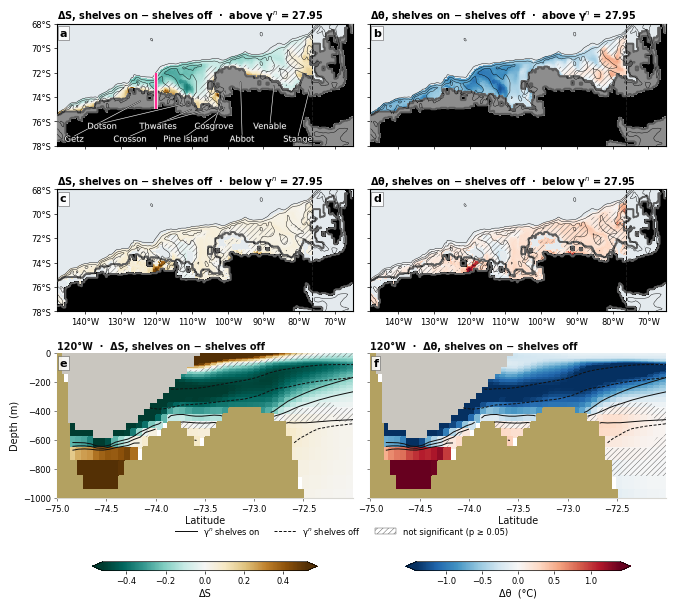

In [20]:
fig